EconoVision - Data Science

In [4]:
#Import Requirements:
import pandas as pd
import numpy as np
import seaborn as sb


Dates appearing more than once: 0
Duplicate date and stock index combinations: 0
Null values across the dataset: 0
Duplicated rows: 0
Average difference in closing price: 1344.7596356842596
Summing values where Daily low > daily high: 0


<Axes: >

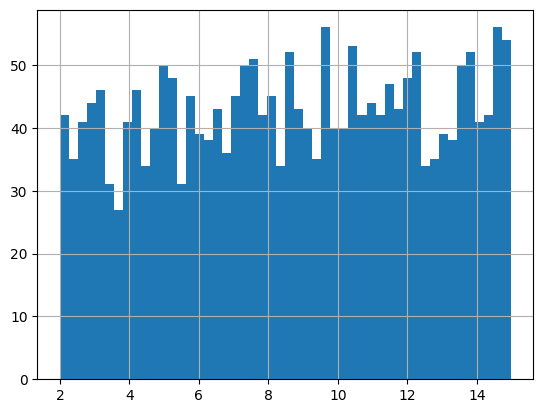

In [5]:
#DATA OBSERVATION/CLEANING

df = pd.read_csv("finance_economics_dataset.csv", parse_dates=["Date"])

#Setting the date column as the dataframe index so you can index rows by date
df = df.sort_values(by="Date").reset_index(drop=True)
#Check column datatypes to ensure they are either float64 or int64
#print(f"Column types: {df.dtypes}")

#Check if values are duplicates
print(f"Dates appearing more than once: {df['Date'].duplicated().sum()}")

print("Duplicate date and stock index combinations:",
      df.duplicated(subset=['Date', 'Stock Index']).sum())

df['Date'].duplicated(keep = False)
df = df[df['Date'].dt.dayofweek < 5]
#check for null values in the df
print(f"Null values across the dataset: {df.isnull().sum().sum()}")
print(f"Duplicated rows: {df.duplicated().sum()}")
# df.describe()
# df.plot(subplots=True, figsize=(10, 12))

#remove weekend dates:

#Verifying that the data is synthetic: IRL, the closing price of a stock shouldn't be varying by much. Here, I can see that it actually varies by a large quantity.
print(f"Average difference in closing price: {df["Close Price"].diff().abs().mean()}")
print(f"Summing values where Daily low > daily high: {(df["Daily Low"] > df["Daily High"]).sum()}")
df["Unemployment Rate (%)"].hist(bins=50)

**Findings: **
From this graph, I've concluded that the dataset is most likely synthetic, or that the data has been randomly generated. Why? Because real datasets would follow gradual patterns rather than this static. Stock prices would follow from the previous day's close price, rather than jump so dramatically from day to day. Looking at 2008 -when the 2008 housing market crash occurred- I can see that columns like unemployment and interest rates don't vary much, which is contrary to what really happened during that period.

In [6]:
# Analyzing Dataset

print("DATASET INFORMATION")
df.info()

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nNUMERICAL SUMMARY")
display(df.describe().T.round(2))

print("\nSTOCK INDICES")
display(df["Stock Index"].value_counts())

print("\nDATE RANGE")
dates = pd.to_datetime(df["Date"], errors="coerce")

print("First date:", dates.min())
print("Last date:", dates.max())



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
Index: 2142 entries, 2 to 2999
Data columns (total 24 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   Date                                   2142 non-null   datetime64[ns]
 1   Stock Index                            2142 non-null   object        
 2   Open Price                             2142 non-null   float64       
 3   Close Price                            2142 non-null   float64       
 4   Daily High                             2142 non-null   float64       
 5   Daily Low                              2142 non-null   float64       
 6   Trading Volume                         2142 non-null   int64         
 7   GDP Growth (%)                         2142 non-null   float64       
 8   Inflation Rate (%)                     2142 non-null   float64       
 9   Unemployment Rate (%)                  2142 non-

,count,mean,min,25%,50%,75%,max,std
Date,2142,2004-02-08 21:36:48.403361408,2000-01-03 00:00:00,2002-01-21 06:00:00,2004-02-09 12:00:00,2006-02-27 18:00:00,2008-03-18 00:00:00,NaN
Open Price,2142.0,2987.41993,1000.12,1996.5675,2961.44,3995.715,4998.23,1160.328743
Close Price,2142.0,2986.413693,954.52,1995.5125,2974.965,3991.175,5034.13,1160.383245
Daily High,2142.0,3023.967348,1012.13,2036.4175,2998.905,4034.21,5076.19,1160.19162
Daily Low,2142.0,2949.535817,917.17,1956.9975,2932.415,3951.06,4977.06,1160.040722
Trading Volume,2142.0,501569951.333333,2436953.0,253814435.75,496268100.5,747982557.75,999977078.0,285440394.358487
GDP Growth (%),2142.0,2.616909,-4.99,-1.02,2.745,6.27,10.0,4.279842
Inflation Rate (%),2142.0,5.088319,0.02,2.5925,5.095,7.565,10.0,2.919208
Unemployment Rate (%),2142.0,8.681027,2.0,5.4625,8.73,11.8875,14.98,3.744792
Interest Rate (%),2142.0,5.26782,0.5,2.9125,5.37,7.54,10.0,2.73259



STOCK INDICES


,count
Stock Index,
NASDAQ,739
S&P 500,735
Dow Jones,668



DATE RANGE
First date: 2000-01-03 00:00:00
Last date: 2008-03-18 00:00:00


Economic Indicator #1: Unemployment Rate



In [7]:
# UNEMPLOYMENT RATE

# Calculating Pearson coefficient between Unemployment Rate and Closing Price

correlation = df['Unemployment Rate (%)'].corr(df['Close Price'])

print("Correlation between Unemployment Rate and Close Price:", correlation)

Correlation between Unemployment Rate and Close Price: 0.010184019022564569


The Peason correlation was 0.01018, meaning there is a very weak relationship between unemployment and stock closing prices. Therefore, changes in the Unemployment Rate do not appear to have a meaningful linear relationship with stock closing prices during the period examined.

In [8]:
# Is this a statistically significant correlation?

from scipy.stats import pearsonr

r, p_value = pearsonr(
    df['Unemployment Rate (%)'],
    df['Close Price']
)

print("Pearson correlation:", round(r, 5))
print("P-value:", p_value)

if p_value < 0.05:
    print("The correlation is statistically significant.")
else:
    print("The correlation is not statistically significant.")


Pearson correlation: 0.01018
P-value: 0.6375898433353446
The correlation is not statistically significant.


The P-value of the Pearson correlation between Unemployment Rate and stock closing prices was 0.638, meaning the correlation is not statistically significant because the p-value is greater than 0.05. Our null hypothesis was that there is no statistically significant relationship between the Unemployment Rate and Stock Closing Prices. Because our results were not statistically significant, we fail to reject the null hypothesis. Therefore, there is insufficient statistical evidence of a significant linear relationship between Unemployment Rate and Stock Closing Prices. Next steps would be to investigate why this data set doesn't have evidence of a statistically significant relationship between the two factors and to compare to a real-world dataset.

In [9]:
# Extra imports + helper functions

import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

sb.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

# Column names used a lot
CLOSE = "Close Price"
GDP, INF, UNEMP, RATE = "GDP Growth (%)", "Inflation Rate (%)", "Unemployment Rate (%)", "Interest Rate (%)"
MACRO = [GDP, INF, UNEMP, RATE]

def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, np.nan, y_true))) * 100

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def score(name, y_true, y_pred, **extra):
    # One row of the results table: MAE, RMSE, MAPE (the three metrics the project asks for)
    return {"Model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": rmse(y_true, y_pred),
            "MAPE (%)": mape(y_true, y_pred), **extra}

The earlier cells showed no nulls or duplicates. We just need to see a clean DatetimeIndex with a known frequency, and outliers.

In [10]:
# Consistent time index: business days only (weekends were removed earlier)
ts = df.set_index("Date").sort_index()

all_bdays = pd.bdate_range(ts.index.min(), ts.index.max())
missing_bdays = all_bdays.difference(ts.index)
print(f"Business days in range: {len(all_bdays)} | rows we have: {len(ts)} | missing business days: {len(missing_bdays)}")

num_cols = ts.select_dtypes(include="number").columns.tolist()

# asfreq('B') adds a row for any missing business day; interpolate fills it using the surrounding dates.
# (If nothing is missing this changes nothing, which is what we expect here.)
ts = ts.asfreq("B")
ts[num_cols] = ts[num_cols].interpolate(method="time")
ts["Stock Index"] = ts["Stock Index"].ffill()
print("Nulls after alignment:", int(ts.isnull().sum().sum()))

Business days in range: 2142 | rows we have: 2142 | missing business days: 0
Nulls after alignment: 0


In [11]:
# Outliers: IQR rule (value more than 1.5 x IQR outside the middle 50%)
q1, q3 = ts[num_cols].quantile(0.25), ts[num_cols].quantile(0.75)
iqr = q3 - q1
outlier_counts = ((ts[num_cols] < q1 - 1.5 * iqr) | (ts[num_cols] > q3 + 1.5 * iqr)).sum()
print("Columns with IQR outliers:")
print(outlier_counts[outlier_counts > 0] if (outlier_counts > 0).any() else "None: every column stays inside the IQR fences")

# Monthly version of the data: macro indicators move slowly, so monthly is the natural 'common frequency'
monthly = ts[num_cols].resample("MS").mean()
print("\nMonthly table shape:", monthly.shape, "| from", monthly.index.min().date(), "to", monthly.index.max().date())

Columns with IQR outliers:
None: every column stays inside the IQR fences

Monthly table shape: (99, 22) | from 2000-01-01 to 2008-03-01


No rows are removed or clipped. The IQR check (above) found nothing that needs handling, and since the earlier analysis suggests the data is synthetic, there is no real-world event to justify removing a value. We keep a daily (business-day) table for stock modelling and a monthly table for the macro/VAR modelling, which gives every indicator one common frequency.

In [12]:
feat = ts.copy()

# returns / transformations (stabilise the series)
feat["log_ret"] = np.log(feat[CLOSE]).diff()          # log return
feat["pct_change"] = feat[CLOSE].pct_change()          # percentage change

# trend & volatility
feat["ma_5"] = feat[CLOSE].rolling(5).mean()
feat["ma_20"] = feat[CLOSE].rolling(20).mean()
feat["vol_20"] = feat["log_ret"].rolling(20).std()     # 20-day rolling volatility

# spreads
feat["hl_spread"] = feat["Daily High"] - feat["Daily Low"]
feat["oc_spread"] = feat[CLOSE] - feat["Open Price"]

# lags
for k in range(1, 6):
    feat[f"close_lag{k}"] = feat[CLOSE].shift(k)
for k in (1, 2, 3):
    feat[f"ret_lag{k}"] = feat["log_ret"].shift(k)

# differenced macro indicators
for c in MACRO:
    feat[f"{c} diff"] = feat[c].diff()

# calendar
feat["month"] = feat.index.month
feat["dayofweek"] = feat.index.dayofweek

# targets: tomorrow's close (regression) and whether it goes up (classification)
feat["target_close"] = feat[CLOSE].shift(-1)
feat["target_up"] = (feat["target_close"] > feat[CLOSE]).astype(int)

feat = feat.dropna()   # drops the first ~20 rows (rolling windows) and the last row (no 'tomorrow')
print("Feature table:", feat.shape)
feat[[CLOSE, "log_ret", "ma_5", "ma_20", "vol_20", "hl_spread", "close_lag1", "target_close"]].head()

Feature table: (2121, 46)


,Close Price,log_ret,ma_5,ma_20,vol_20,hl_spread,close_lag1,target_close
Date,,,,,,,,
2000-01-31,3578.83,-0.085728,2694.106,2826.3130,0.859169,78.94,3899.17,1772.67
2000-02-01,1772.67,-0.702549,2802.450,2681.9230,0.851044,51.04,3578.83,3264.57
2000-02-02,3264.57,0.610641,2911.726,2746.0425,0.840974,35.48,1772.67,2862.17
2000-02-03,2862.17,-0.131548,3075.482,2782.9130,0.841615,39.51,3264.57,4898.08
2000-02-04,4898.08,0.537263,3275.264,2827.9970,0.838229,51.94,2862.17,1468.10


The feature table contains 2,121 rows and 46 columns, reflecting the expected drop of the first 20 rows (needed to initialize the 20-day rolling averages and volatility) and the final row (which lacks a next-day `target_close`). Checking consecutive dates confirms that the shifts are aligned without leakage—for instance, `Close Price` on 2000-01-31 (`3578.83`) appears as `close_lag1` on 2000-02-01, and `target_close` (`1772.67`) matches the following day's close.

The engineered values also reinforce that this dataset is synthetic and mixes indices across rows. Daily log returns (`log_ret`) swing sharply between `-0.70` and `+0.61` in just a few days, keeping 20-day rolling volatility (`vol_20`) around `0.84–0.86`, which is unrealistically high for real stock markets. Furthermore, the intraday spreads (`hl_spread` of around 35 to 79 points) are small compared to the multi-thousand-point jumps between `Close Price` and `target_close`, while `ma_5` and `ma_20` smooth those erratic spikes back toward the overall mean (around 2,986).

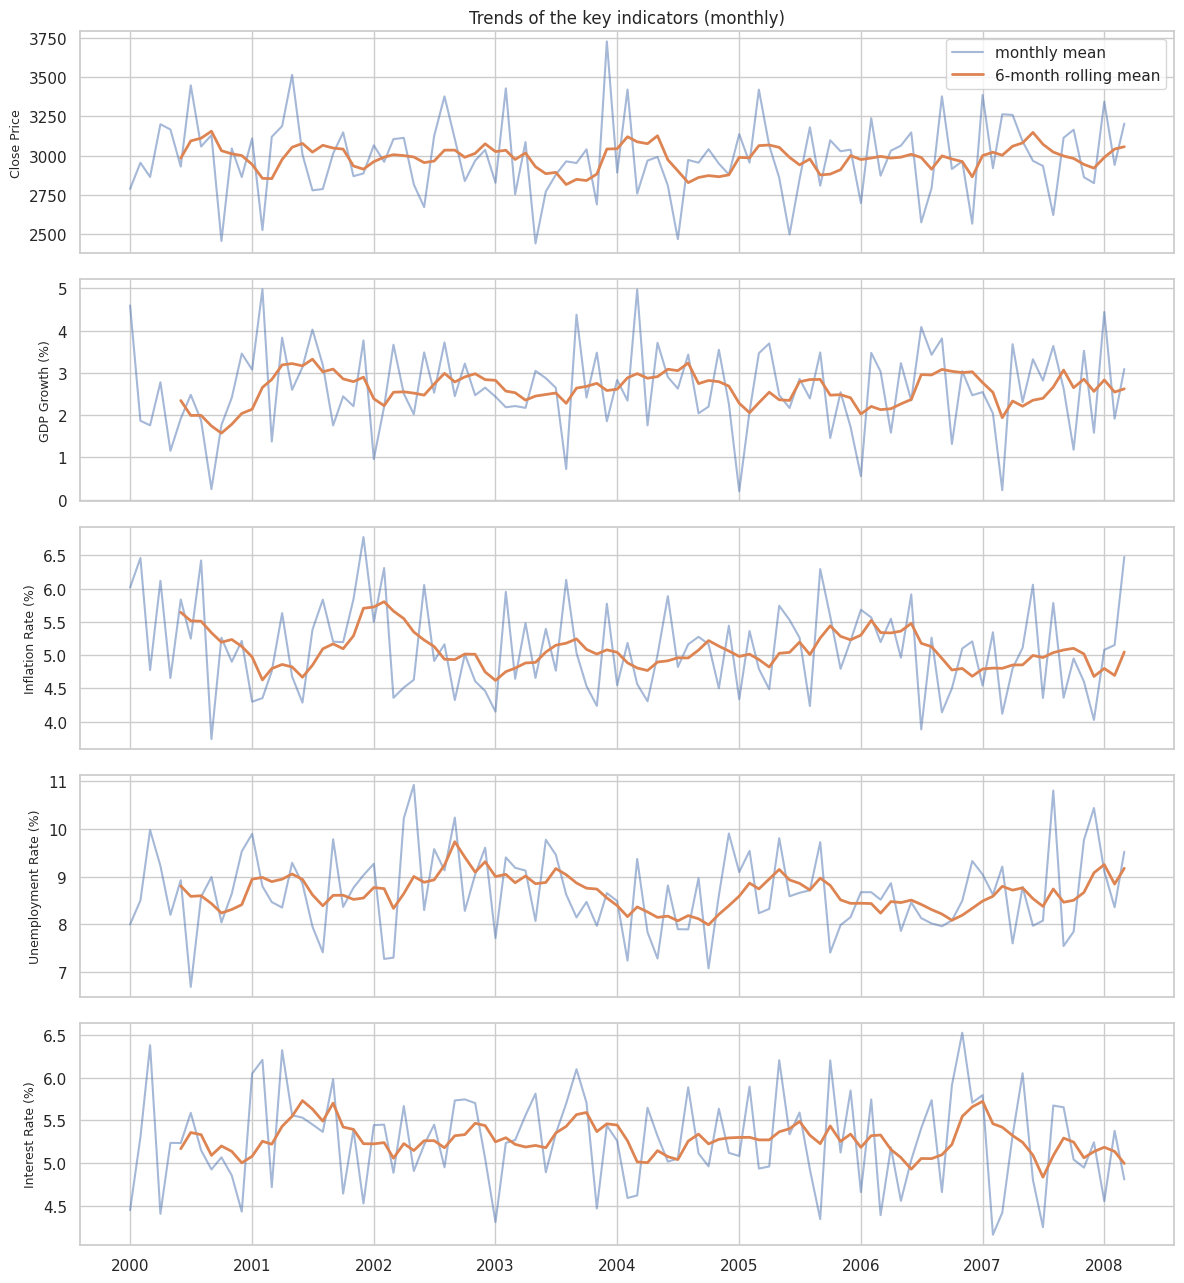

In [13]:
# Long-term trends: monthly averages with a 6-month rolling mean
fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True)
for ax, c in zip(axes, [CLOSE] + MACRO):
    ax.plot(monthly.index, monthly[c], alpha=0.5, label="monthly mean")
    ax.plot(monthly.index, monthly[c].rolling(6).mean(), linewidth=2, label="6-month rolling mean")
    ax.set_ylabel(c, fontsize=9)
axes[0].legend(loc="upper right")
axes[0].set_title("Trends of the key indicators (monthly)")
plt.tight_layout(); plt.show()

None of the five indicators show a meaningful long-term upward or downward trend between 2000 and 2008. While the monthly averages fluctuate sharply from month to month (for example, `Close Price` bounces between roughly 2,450 and 3,750, and `GDP Growth (%)` swings between 0.3% and 5.0%), the bold 6-month rolling mean remains flat around each variable's overall average (3,000 for Close Price, 2.6% for GDP Growth, 5.1% for Inflation, 8.7% for Unemployment, and 5.3% for Interest Rate). Even entering 2008, there are no macroeconomic shifts or market cycles, indicating that all five series behave as stationary random noise around fixed means.

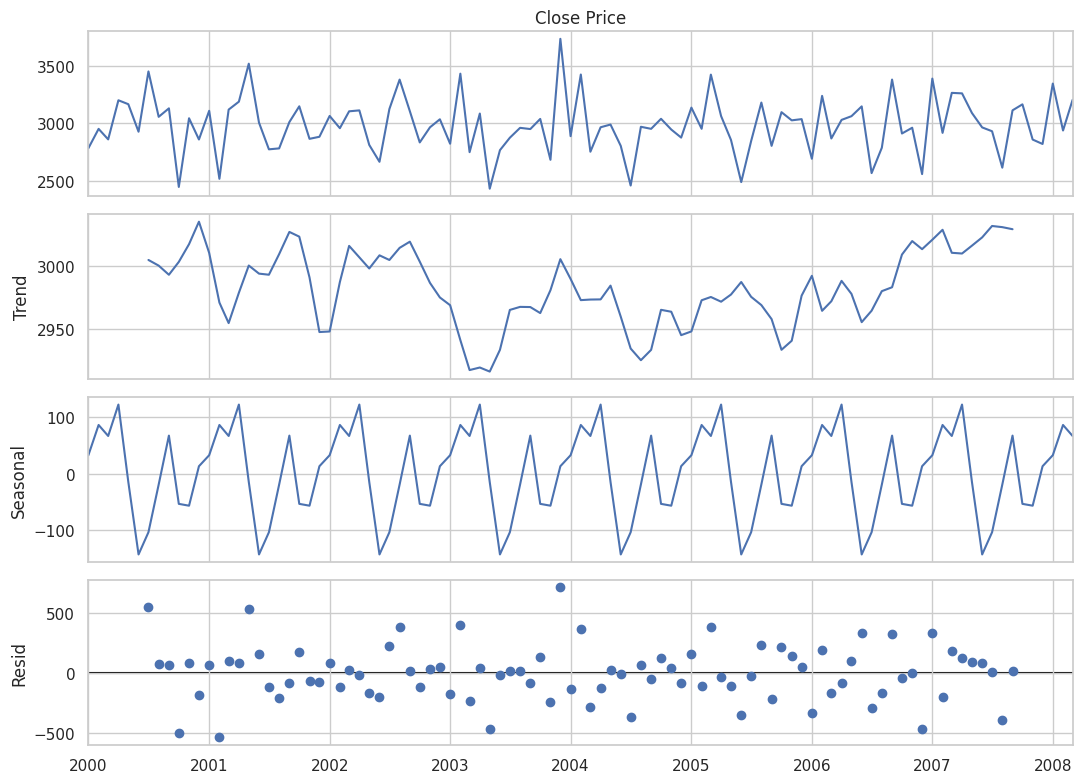

In [14]:
# Seasonality: decomposition of the monthly average close (additive: trend + seasonal + residual)
from statsmodels.tsa.seasonal import seasonal_decompose

decomp = seasonal_decompose(monthly[CLOSE], model="additive", period=12)
fig = decomp.plot(); fig.set_size_inches(11, 8); plt.tight_layout(); plt.show()

The decomposition shows little to no genuine seasonality in the monthly `Close Price`. While the `Seasonal` panel extracts a repeating 12-month wave swinging between roughly -140 and +125 points, the `Resid` (residual) panel ranges from about -530 to +710 points—more than four to five times larger than the seasonal component. Meanwhile, the `Trend` line stays confined within a narrow band (2,925 to 3,030). Because `seasonal_decompose` forces a repeating annual cycle onto whatever series it is given, the small seasonal pattern here is just leftover noise rather than a real calendar effect.

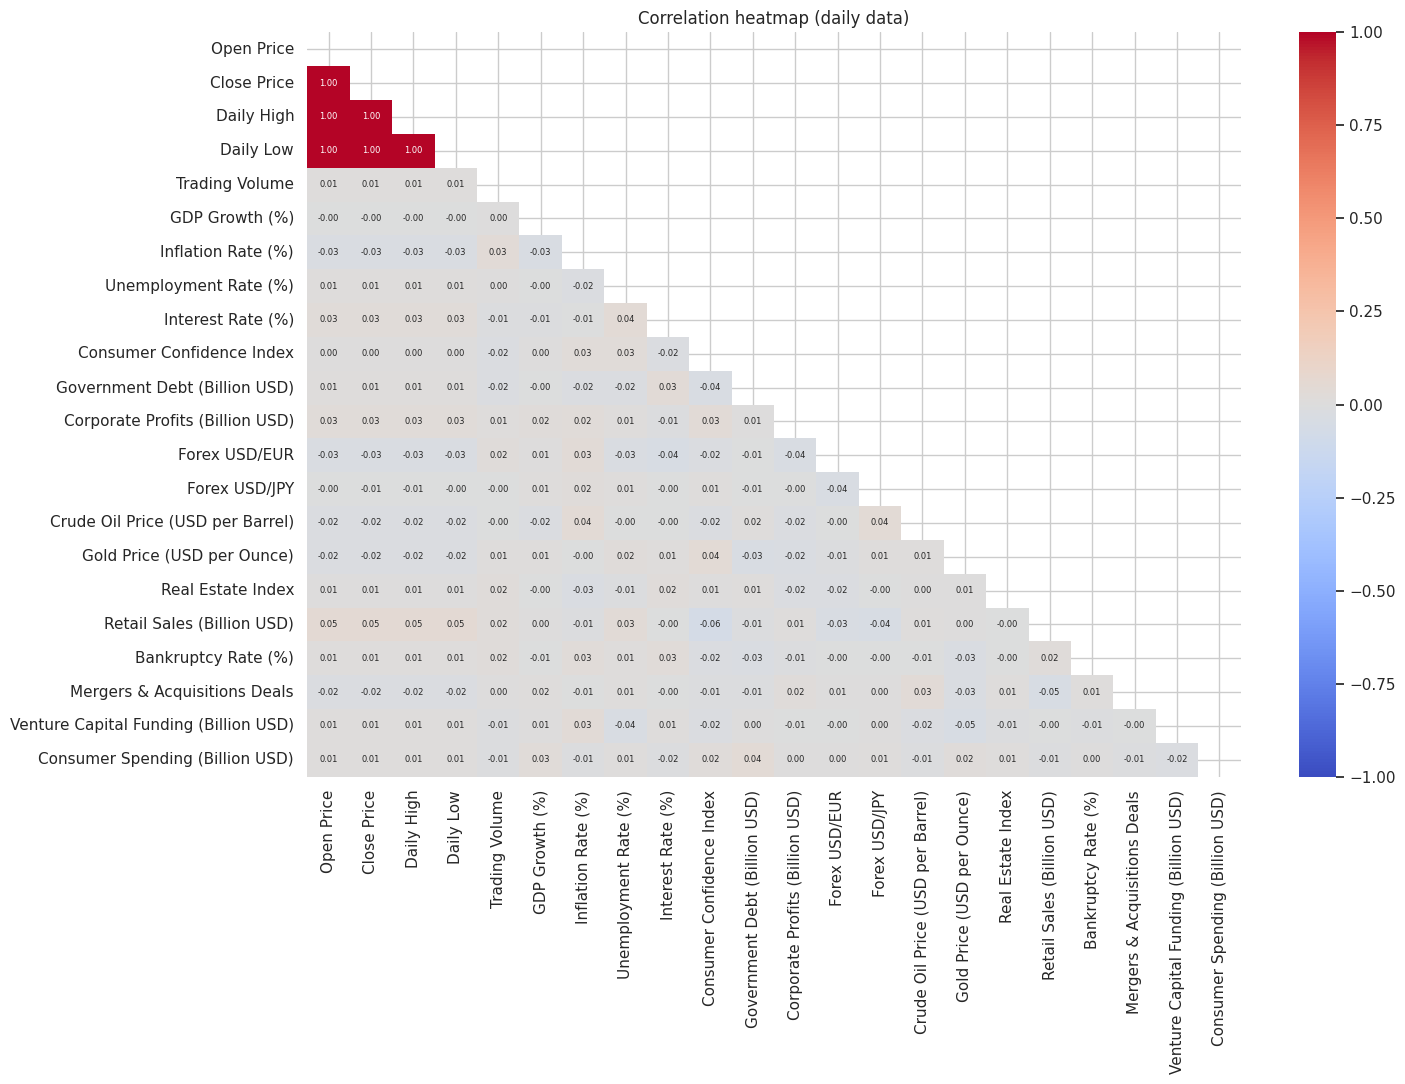

In [15]:
# Correlation matrix of every numeric column
plt.figure(figsize=(15, 11))
corr = ts[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sb.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 6}, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap (daily data)")
plt.tight_layout(); plt.show()

The heatmap splits into two stark patterns: the four daily price columns (`Open Price`, `Close Price`, `Daily High`, and `Daily Low`) have pairwise correlations of `1.00` because they are generated close to one another on the same day, whereas every other pair of variables in the entire dataset sits near `0.00` (all between `-0.05` and `+0.06`). Specifically, `Close Price` has virtually zero linear correlation with `GDP Growth (%)` (0.00), `Unemployment Rate (%)` (0.01), `Inflation Rate (%)` (0.03), and `Interest Rate (%)` (0.03), and even standard macroeconomic pairs like GDP growth and unemployment (`0.00`) are uncorrelated. This confirms that outside of the four intraday price columns, all variables were generated independently of each other.

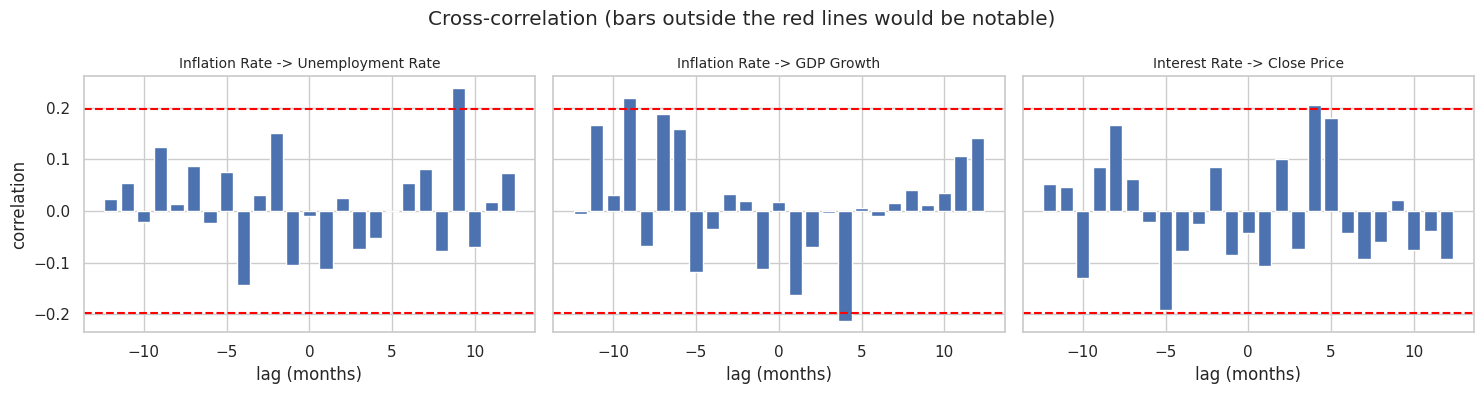

In [16]:
# Cross-correlation: does x today relate to y k months later?  (k > 0: x leads y)
def ccf(x, y, max_lag=12):
    return pd.Series({k: x.corr(y.shift(-k)) for k in range(-max_lag, max_lag + 1)})

pairs_to_plot = [(INF, UNEMP), (INF, GDP), (RATE, CLOSE)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
band = 1.96 / np.sqrt(len(monthly))        # approximate 95% 'no relationship' band
for ax, (x, y) in zip(axes, pairs_to_plot):
    cc = ccf(monthly[x], monthly[y])
    ax.bar(cc.index, cc.values)
    ax.axhline(band, color="red", ls="--"); ax.axhline(-band, color="red", ls="--")
    ax.set_title(f"{x.split(' (')[0]} -> {y.split(' (')[0]}", fontsize=10)
    ax.set_xlabel("lag (months)")
axes[0].set_ylabel("correlation")
plt.suptitle("Cross-correlation (bars outside the red lines would be notable)")
plt.tight_layout(); plt.show()

Bars that stay inside the red dashed band mean the relationship at that lag is indistinguishable from chance. This lines up with the earlier Pearson test (r = 0.01, p = 0.64 for unemployment vs close).

interpretation

We train on the first 80% of the dates and test on the last 20% for train and test split.

In [17]:
split = int(len(feat) * 0.8)
train, test = feat.iloc[:split], feat.iloc[split:]
print(f"Train: {train.index.min().date()} -> {train.index.max().date()}  ({len(train)} days)")
print(f"Test : {test.index.min().date()} -> {test.index.max().date()}  ({len(test)} days)")

lag_cols = [CLOSE] + [f"close_lag{k}" for k in range(1, 6)]
eng_cols = (lag_cols + ["ma_5", "ma_20", "vol_20", "hl_spread", "oc_spread", "log_ret",
                        "ret_lag1", "ret_lag2", "ret_lag3", "Open Price", "Trading Volume"]
            + MACRO + [f"{c} diff" for c in MACRO] + ["month", "dayofweek"])

y_train, y_test = train["target_close"], test["target_close"]

Train: 2000-01-31 -> 2006-07-31  (1696 days)
Test : 2006-08-01 -> 2008-03-17  (425 days)


In [18]:
daily_results = []
preds = {} #predictions

# baselines
preds["Naive (tomorrow = today)"] = test[CLOSE].values
preds["Mean (train average)"] = np.full(len(test), y_train.mean())

# ML models
candidates = {
    "Linear (lags)":        (make_pipeline(StandardScaler(), LinearRegression()), lag_cols),
    "Ridge (lags)":         (make_pipeline(StandardScaler(), Ridge(alpha=10)), lag_cols),
    "RandomForest (lags)":  (RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1), lag_cols),
    "Linear (engineered)":  (make_pipeline(StandardScaler(), LinearRegression()), eng_cols),
    "Ridge (engineered)":   (make_pipeline(StandardScaler(), Ridge(alpha=10)), eng_cols),
    "RandomForest (engineered)": (RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1), eng_cols),
}

fitted = {}
train_sigma = {}
for name, (model, cols) in candidates.items():
    model.fit(train[cols], y_train)
    fitted[name] = (model, cols)
    preds[name] = model.predict(test[cols])
    train_pred = model.predict(train[cols])
    train_sigma[name] = np.std(y_train - train_pred)          # used for confidence bands later
    daily_results.append(score(name, y_test, preds[name], **{"Train RMSE": rmse(y_train, train_pred)}))

for name in ["Naive (tomorrow = today)", "Mean (train average)"]:
    daily_results.append(score(name, y_test, preds[name]))

daily_table = pd.DataFrame(daily_results).sort_values("RMSE").reset_index(drop=True)
daily_table.round(2)

,Model,MAE,RMSE,MAPE (%),Train RMSE
0,RandomForest (engineered),1022.15,1178.52,44.20,654.52
1,Ridge (engineered),1027.84,1179.61,44.44,1141.78
2,Linear (engineered),1028.60,1181.24,44.49,1141.08
3,RandomForest (lags),1019.42,1181.81,43.86,752.16
4,Linear (lags),1032.75,1182.78,44.62,1151.60
5,Ridge (lags),1032.76,1182.78,44.62,1151.60
6,Mean (train average),1033.38,1183.94,44.61,NaN
7,Naive (tomorrow = today),1435.00,1733.92,59.49,NaN


None of the trained models meaningfully beat the `Mean (train average)` baseline (`RMSE` 1183.94, `MAE` 1033.38, `MAPE` 44.61%). All six ML models cluster tightly between 1178.52 and 1182.78 `RMSE`—at best improving on the mean baseline by just 5.42 points (0.46%) with `RandomForest (engineered)`—which shows that neither past lags nor the engineered/macroeconomic features contain real predictive signal for tomorrow's close. Meanwhile, `Naive (tomorrow = today)` performs substantially worse (`RMSE` 1733.92, `MAPE` 59.49%) because consecutive rows behave like independent random draws rather than a continuous price series, so carrying today's value forward introduces extra variance.

Comparing `Train RMSE` to test `RMSE` also highlights clear overfitting in the Random Forest models: `RandomForest (engineered)` drops to 654.52 on training data but jumps to 1178.52 on test data (a 524-point gap), and `RandomForest (lags)` shows a similar jump from 752.16 to 1181.81. In contrast, the `Linear` and `Ridge` models show almost no train-to-test gap (1141–1152 train vs. 1180–1183 test) because they avoid memorizing noise and effectively predict near the training average.

In [19]:
from statsmodels.tsa.api import VAR

var_cols = [CLOSE] + MACRO
mdf = monthly[var_cols].dropna()
n_test = int(len(mdf) * 0.2)
m_train, m_test = mdf.iloc[:-n_test], mdf.iloc[-n_test:]

# 1) choose the lag order with AIC (at least 1)
var_model = VAR(m_train)
order = var_model.select_order(maxlags=4)
p = max(1, order.selected_orders["aic"])
print("Lag order chosen by AIC:", p)

# 2) fit + forecast with a 95% interval
var_res = var_model.fit(p)
fc, lo, hi = var_res.forecast_interval(m_train.values[-p:], steps=n_test, alpha=0.05)
fc = pd.DataFrame(fc, index=m_test.index, columns=var_cols)
lo = pd.DataFrame(lo, index=m_test.index, columns=var_cols)
hi = pd.DataFrame(hi, index=m_test.index, columns=var_cols)

# 3) evaluate each indicator against two baselines
rows = []
for c in var_cols:
    mean_fc = np.full(len(m_test), m_train[c].mean())
    naive_fc = np.full(len(m_test), m_train[c].iloc[-1])
    r_var, r_mean = rmse(m_test[c], fc[c]), rmse(m_test[c], mean_fc)
    rows.append({"Indicator": c,
                 "VAR MAE": mean_absolute_error(m_test[c], fc[c]), "VAR RMSE": r_var, "VAR MAPE (%)": mape(m_test[c], fc[c]),
                 "Mean-baseline RMSE": r_mean, "Naive RMSE": rmse(m_test[c], naive_fc),
                 "VAR beats mean?": "yes" if r_var < r_mean else "no"})
var_table = pd.DataFrame(rows)
var_table.round(3)

Lag order chosen by AIC: 1


,Indicator,VAR MAE,VAR RMSE,VAR MAPE (%),Mean-baseline RMSE,Naive RMSE,VAR beats mean?
0,Close Price,192.467,237.796,6.306,240.588,338.763,yes
1,GDP Growth (%),0.835,1.034,86.920,1.031,1.316,no
2,Inflation Rate (%),0.536,0.674,11.267,0.679,0.727,yes
3,Unemployment Rate (%),0.744,0.907,8.331,0.909,1.173,yes
4,Interest Rate (%),0.545,0.641,10.822,0.641,0.828,yes


Although four of the five indicators technically register a "yes" for beating the mean baseline, the VAR RMSE scores are virtually identical to simply predicting the training average (for example, `237.80` vs. `240.59` for Close Price and `0.641` vs. `0.641` for Interest Rate). This confirms that modeling the indicators together provides no real predictive advantage over a flat average in this synthetic dataset.

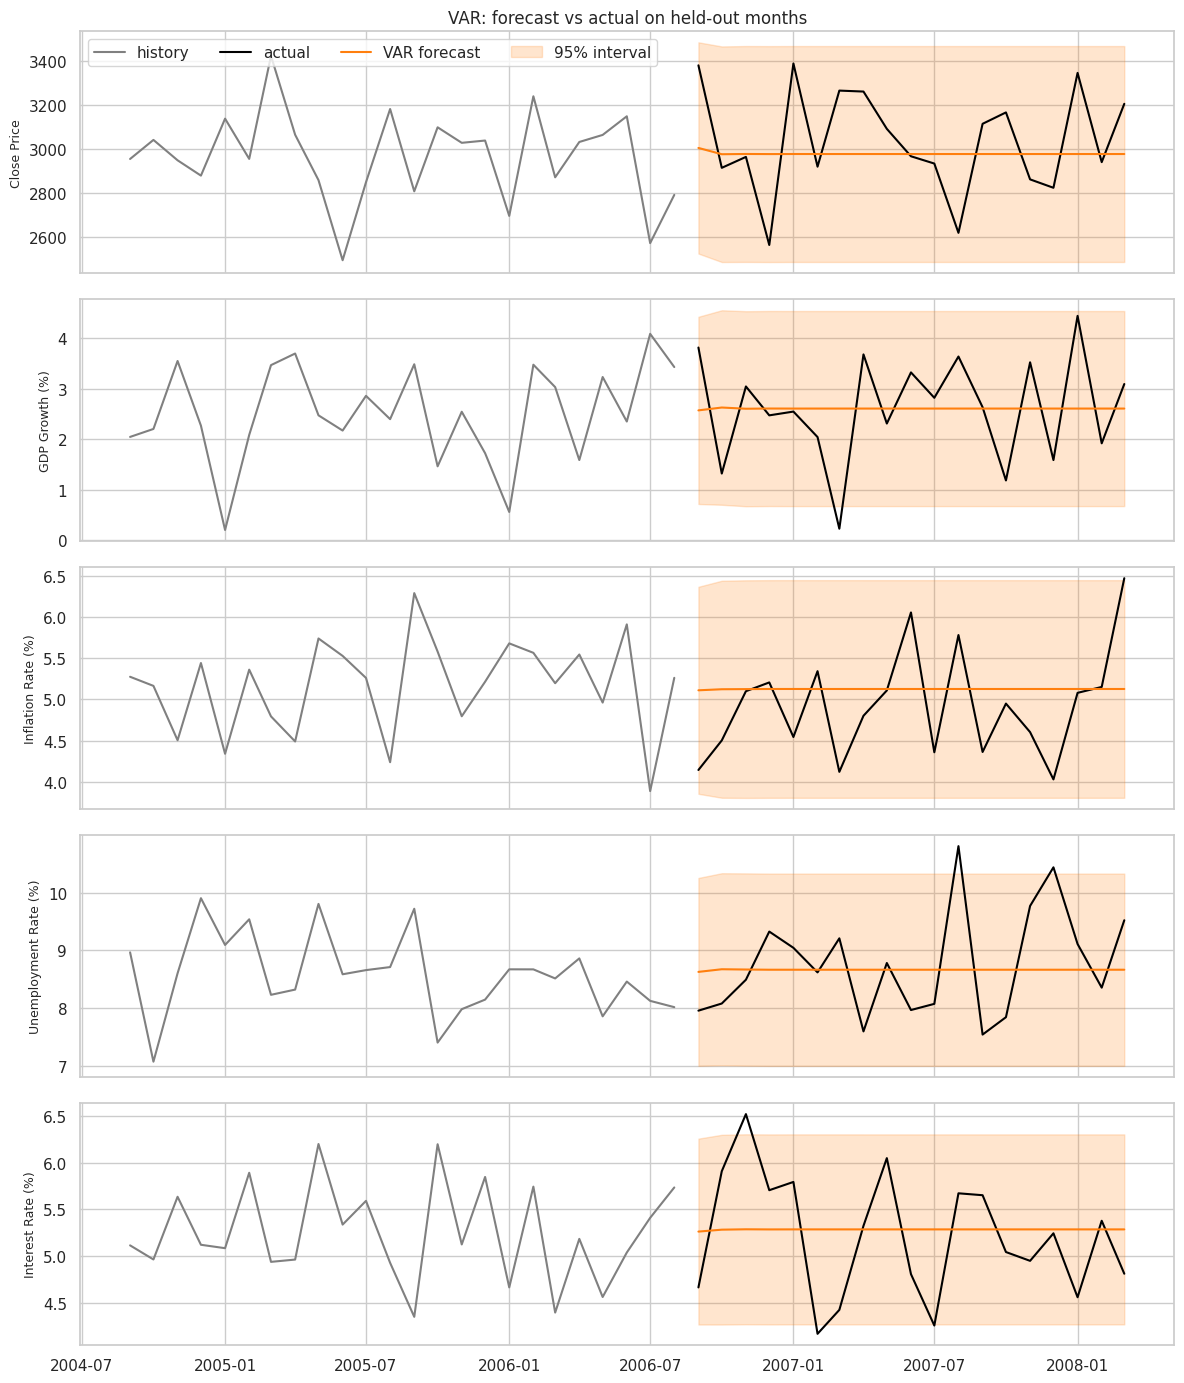

In [20]:
# Forecast vs actual with 95% intervals
fig, axes = plt.subplots(len(var_cols), 1, figsize=(12, 14), sharex=True)
for ax, c in zip(axes, var_cols):
    hist = m_train[c].iloc[-24:]
    ax.plot(hist.index, hist, color="gray", label="history")
    ax.plot(m_test.index, m_test[c], color="black", label="actual")
    ax.plot(m_test.index, fc[c], color="tab:orange", label="VAR forecast")
    ax.fill_between(m_test.index, lo[c], hi[c], color="tab:orange", alpha=0.2, label="95% interval")
    ax.set_ylabel(c, fontsize=9)
axes[0].legend(ncol=4, loc="upper left")
axes[0].set_title("VAR: forecast vs actual on held-out months")
plt.tight_layout(); plt.show()

Across all five indicators, the orange VAR forecast immediately flattens into a horizontal line at the historical mean while the actual values fluctuate randomly around it. The wide 95% confidence bands simply capture the full spread of the synthetic noise rather than predicting actual month-to-month movements.

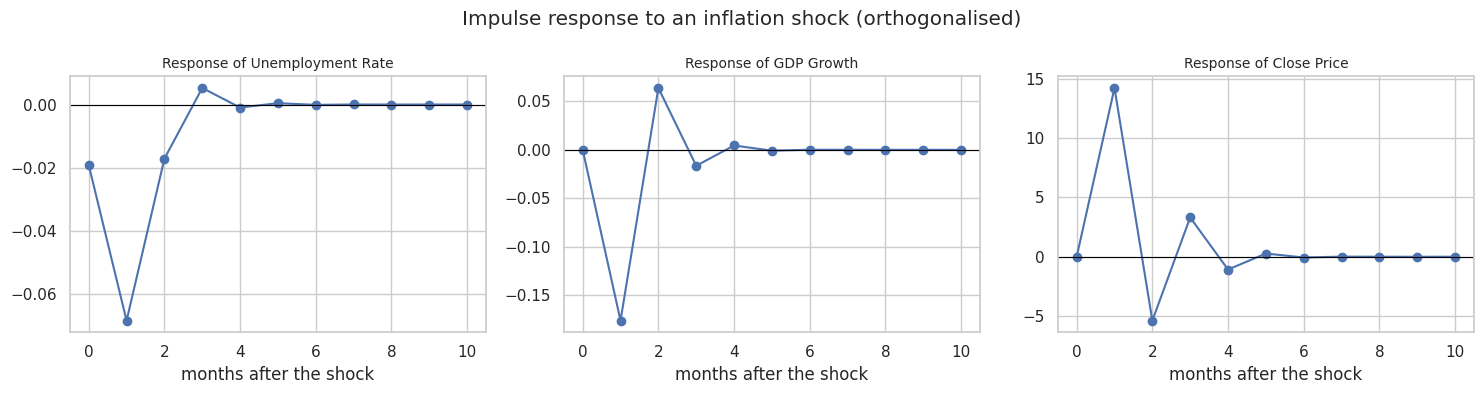

In [21]:
# Impulse response: what happens to unemployment / GDP growth / close after a one-standard-deviation inflation shock?
irf = var_res.irf(10)
orth = irf.orth_irfs # shape (steps+1, response, impulse)
imp = var_cols.index(INF)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, resp in zip(axes, [UNEMP, GDP, CLOSE]):
    ax.plot(range(orth.shape[0]), orth[:, var_cols.index(resp), imp], marker="o")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"Response of {resp.split(' (')[0]}", fontsize=10); ax.set_xlabel("months after the shock")
plt.suptitle("Impulse response to an inflation shock (orthogonalised)")
plt.tight_layout(); plt.show()

The small initial responses in months 1–3 quickly decay to zero by month 5 across all three indicators. Because the VAR model barely differs from the mean baseline, these brief wiggles reflect random noise rather than real macroeconomic relationships.

Windows: (1696, 20, 1) (425, 20, 1)
LSTM: stopped after 9 epochs
GRU: stopped after 11 epochs


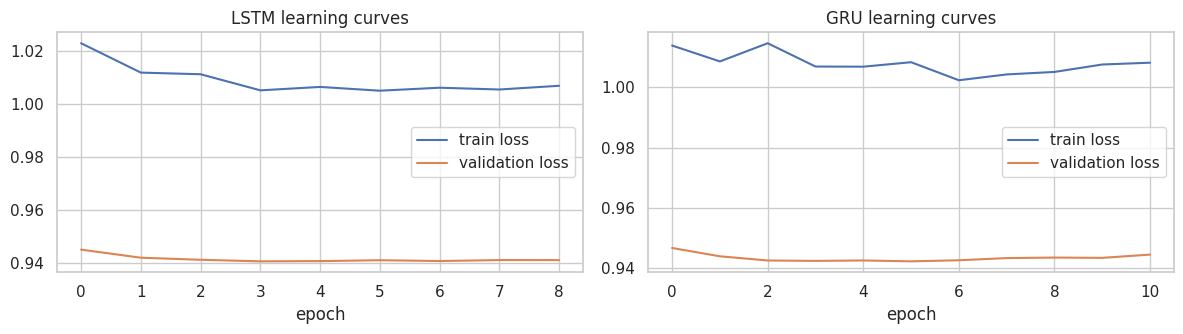

In [22]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(SEED)
WINDOW = 20

s = ts[CLOSE]
scaler = StandardScaler().fit(s.loc[:train.index[-1]].values.reshape(-1, 1))   # train days only
sv = scaler.transform(s.values.reshape(-1, 1)).ravel()
pos = {d: i for i, d in enumerate(s.index)}

def make_windows(dates):
    idx = [pos[d] for d in dates]
    X = np.stack([sv[i - WINDOW + 1: i + 1] for i in idx])[..., None]
    y = np.array([sv[i + 1] for i in idx])
    return X, y

X_tr, y_tr = make_windows(train.index)
X_te, y_te = make_windows(test.index)
print("Windows:", X_tr.shape, X_te.shape)

def build(kind):
    Rnn = layers.LSTM if kind == "LSTM" else layers.GRU
    m = keras.Sequential([layers.Input(shape=(WINDOW, 1)), Rnn(32), layers.Dropout(0.2), layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return m

histories = {}
for kind in ["LSTM", "GRU"]:
    m = build(kind)
    h = m.fit(X_tr, y_tr, epochs=40, batch_size=32, validation_split=0.15, shuffle=False, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    histories[kind] = h.history
    p_te = scaler.inverse_transform(m.predict(X_te, verbose=0)).ravel()
    p_tr = scaler.inverse_transform(m.predict(X_tr, verbose=0)).ravel()
    preds[kind] = p_te
    train_sigma[kind] = np.std(y_train.values - p_tr)
    daily_results.append(score(kind, y_test, p_te, **{"Train RMSE": rmse(y_train, p_tr)}))
    print(f"{kind}: stopped after {len(h.history['loss'])} epochs")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, kind in zip(axes, histories):
    ax.plot(histories[kind]["loss"], label="train loss"); ax.plot(histories[kind]["val_loss"], label="validation loss")
    ax.set_title(f"{kind} learning curves"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

Both the LSTM (stopped after 9 epochs) and GRU (stopped after 11 epochs) learning curves flatten out almost immediately, with training loss stuck near `1.00` and validation loss flat around `0.94`. Because the target series was standardized to a variance of `1.0`, an MSE near `1.0` shows that neither network can extract sequential patterns from the 20-day windows and both effectively default to predicting the average. It stops early simply because the validation error is no longer improving after a few epochs rather than overfitting.

,Rank,Model,MAE,RMSE,MAPE (%),Train RMSE,Skill vs mean (%)
0,1,RandomForest (engineered),1022.15,1178.52,44.20,654.52,0.46
1,2,Ridge (engineered),1027.84,1179.61,44.44,1141.78,0.37
2,3,Linear (engineered),1028.60,1181.24,44.49,1141.08,0.23
3,4,RandomForest (lags),1019.42,1181.81,43.86,752.16,0.18
4,5,Linear (lags),1032.75,1182.78,44.62,1151.60,0.10
5,6,Ridge (lags),1032.76,1182.78,44.62,1151.60,0.10
6,7,LSTM,1032.03,1183.02,44.44,1150.92,0.08
7,8,GRU,1033.25,1183.77,44.50,1150.92,0.01
8,9,Mean (train average),1033.38,1183.94,44.61,NaN,0.00
9,10,Naive (tomorrow = today),1435.00,1733.92,59.49,NaN,-46.45


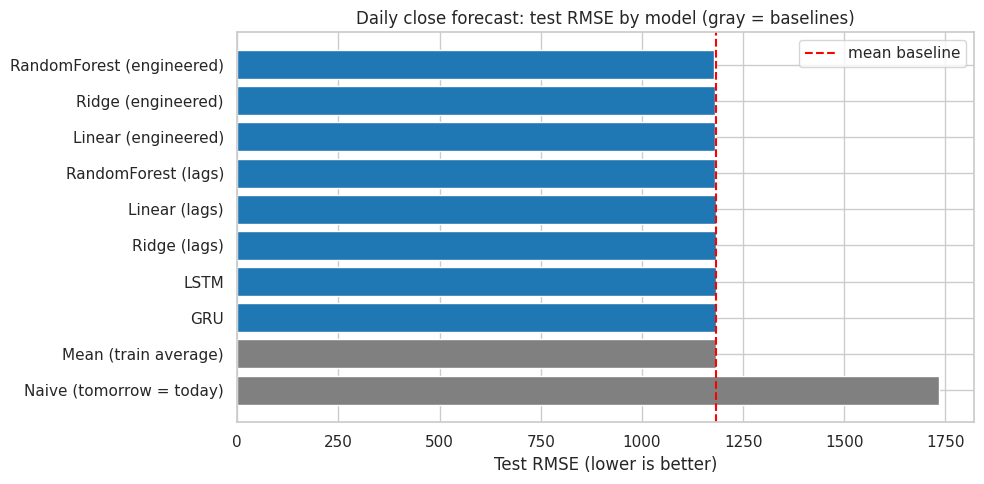

Best trained model: RandomForest (engineered) (RMSE 1178.5 vs baseline 1183.9). It is only 0.5% better than the always-guess-the-average baseline, which is within noise, so effectively no skill.


In [23]:
daily_table = pd.DataFrame(daily_results).sort_values("RMSE").reset_index(drop=True)
mean_rmse = daily_table.loc[daily_table["Model"] == "Mean (train average)", "RMSE"].iloc[0]
daily_table["Skill vs mean (%)"] = (1 - daily_table["RMSE"] / mean_rmse) * 100
daily_table.insert(0, "Rank", range(1, len(daily_table) + 1))
display(daily_table.round(2))

plt.figure(figsize=(10, 5))
colors = ["gray" if m in ("Naive (tomorrow = today)", "Mean (train average)") else "tab:blue" for m in daily_table["Model"]]
plt.barh(daily_table["Model"][::-1], daily_table["RMSE"][::-1], color=colors[::-1])
plt.axvline(mean_rmse, color="red", ls="--", label="mean baseline")
plt.xlabel("Test RMSE (lower is better)"); plt.title("Daily close forecast: test RMSE by model (gray = baselines)"); plt.legend()
plt.tight_layout(); plt.show()

# Automatic one-line summary so the write-up always matches the numbers
real_models = daily_table[~daily_table["Model"].isin(["Naive (tomorrow = today)", "Mean (train average)"])]
best = real_models.iloc[0]
skill = (1 - best["RMSE"] / mean_rmse) * 100
if skill >= 5:
    verdict = f"beats the always-guess-the-average baseline by a meaningful margin ({skill:.1f}%)"
elif skill > 0:
    verdict = f"is only {skill:.1f}% better than the always-guess-the-average baseline, which is within noise, so effectively no skill"
else:
    verdict = "does NOT beat the always-guess-the-average baseline"
print(f"Best trained model: {best['Model']} (RMSE {best['RMSE']:.1f} vs baseline {mean_rmse:.1f}). It {verdict}.")

All eight trained models sit right on the red dashed `Mean (train average)` line (`RMSE` 1183.94), with even the best model (`RandomForest (engineered)`, `RMSE` 1178.52) beating the average by just 0.46%. Both Random Forest models also show clear overfitting (`Train RMSE` of 654.52 and 752.16 vs. 1179–1182 on test), while `Naive (tomorrow = today)` does much worse (`RMSE` 1733.92). Overall, none of the models find real predictive signal in this synthetic data.

In [24]:
def ridge_forecast(train_series, steps, n_lags=3):
    # Univariate Ridge on the series' own lags, forecasting `steps` ahead recursively
    s = train_series.reset_index(drop=True)
    X = pd.concat({f"lag{k}": s.shift(k) for k in range(1, n_lags + 1)}, axis=1).dropna()
    y = s.loc[X.index]
    m = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(X, y)
    hist, out = list(s.values), []
    for _ in range(steps):
        x = pd.DataFrame([[hist[-k] for k in range(1, n_lags + 1)]], columns=X.columns)
        out.append(float(m.predict(x)[0])); hist.append(out[-1])
    return np.array(out)

rows = []
for c in var_cols:
    r = ridge_forecast(m_train[c], len(m_test))
    rows.append({"Indicator": c, "Ridge MAE": mean_absolute_error(m_test[c], r),
                 "Ridge RMSE": rmse(m_test[c], r), "Ridge MAPE (%)": mape(m_test[c], r)})

across = var_table[["Indicator", "VAR MAE", "VAR RMSE", "VAR MAPE (%)", "Mean-baseline RMSE"]].merge(pd.DataFrame(rows), on="Indicator")
across["Best by RMSE"] = across[["VAR RMSE", "Ridge RMSE", "Mean-baseline RMSE"]].idxmin(axis=1).str.replace(" RMSE", "").str.replace("-baseline", " baseline")
across.round(3)

,Indicator,VAR MAE,VAR RMSE,VAR MAPE (%),Mean-baseline RMSE,Ridge MAE,Ridge RMSE,Ridge MAPE (%),Best by RMSE
0,Close Price,192.467,237.796,6.306,240.588,207.998,253.091,6.819,VAR
1,GDP Growth (%),0.835,1.034,86.920,1.031,0.833,1.032,87.409,Mean baseline
2,Inflation Rate (%),0.536,0.674,11.267,0.679,0.523,0.661,10.944,Ridge
3,Unemployment Rate (%),0.744,0.907,8.331,0.909,0.740,0.910,8.272,VAR
4,Interest Rate (%),0.545,0.641,10.822,0.641,0.542,0.637,10.732,Ridge


Although the `Best by RMSE` column splits across `VAR` (Close Price and Unemployment), `Ridge` (Inflation and Interest Rate), and `Mean baseline` (GDP Growth), the RMSE scores across all three approaches are virtually identical for every indicator. Neither multivariate (`VAR`) nor univariate (`Ridge`) models meaningfully beat simply guessing the historical mean on this synthetic data.

In our results, `RandomForest (engineered)` ranks #1 on daily accuracy (`RMSE` 1178.52), while `Ridge (engineered)` is right behind it (`RMSE` 1179.61) with much higher interpretability and no overfitting. Because none of the models beat the mean baseline by a meaningful margin on either daily or monthly data, high-interpretability models like `Ridge` and `VAR` are the clear winners over black-box models (`Random Forest`, `LSTM`, `GRU`) here.

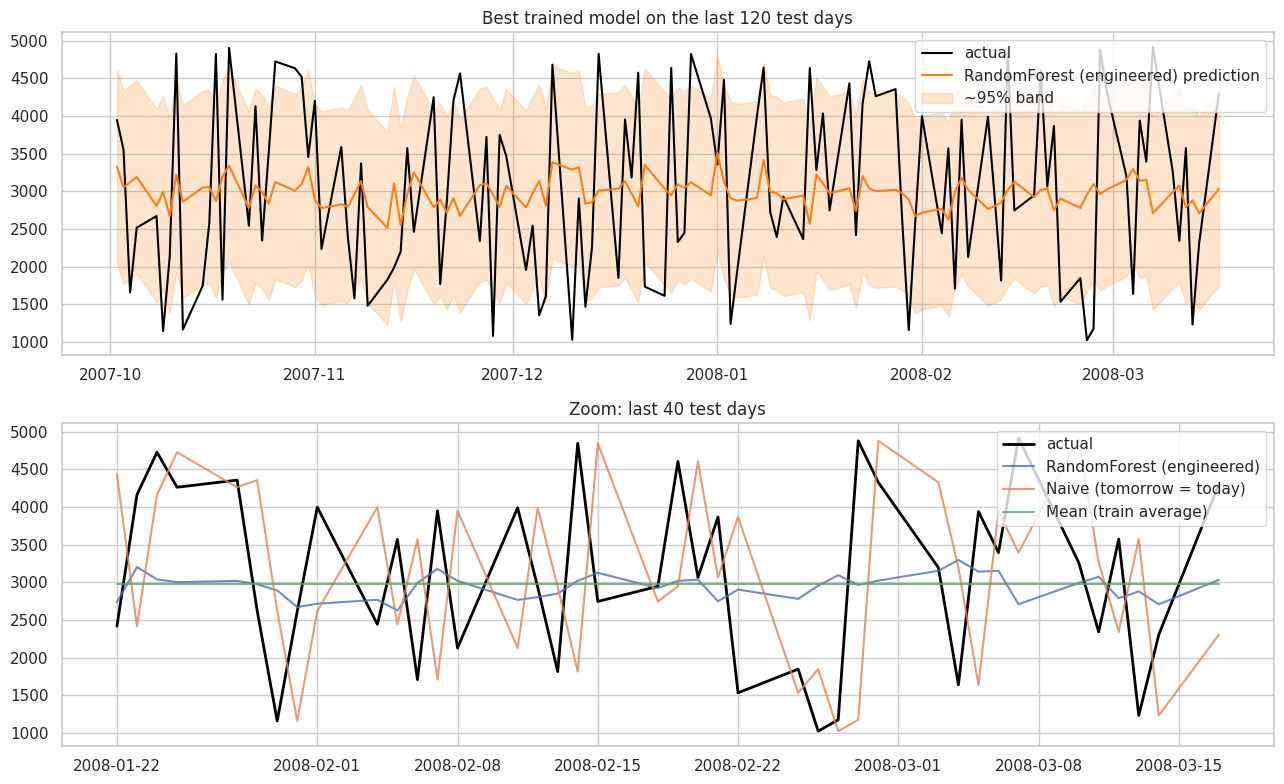

In [25]:
best_name = best["Model"]
n_show = 120
idx = test.index[-n_show:]
pred_show = pd.Series(preds[best_name], index=test.index).loc[idx]
sigma = train_sigma[best_name]
target_dates = test.index[-n_show:]

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
# (a) best model
axes[0].plot(idx, test["target_close"].loc[idx], color="black", label="actual")
axes[0].plot(idx, pred_show, color="tab:orange", label=f"{best_name} prediction")
axes[0].fill_between(idx, pred_show - 1.96 * sigma, pred_show + 1.96 * sigma, color="tab:orange", alpha=0.2, label="~95% band")
axes[0].set_title(f"Best trained model on the last {n_show} test days"); axes[0].legend(loc="upper right")

# (b) several models vs the baseline on a shorter window
short = test.index[-40:]
axes[1].plot(short, test["target_close"].loc[short], color="black", lw=2, label="actual")
for name in [best_name, "Naive (tomorrow = today)", "Mean (train average)"]:
    axes[1].plot(short, pd.Series(preds[name], index=test.index).loc[short], label=name, alpha=0.8)
axes[1].set_title("Zoom: last 40 test days"); axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

In the top plot, the `RandomForest (engineered)` predictions stay clustered around 3,000 while the actual prices swing wildly between 1,000 and 5,000, repeatedly breaking outside the 95% band (showing the model is overconfident due to overfitting). In the zoomed-in bottom plot, the Random Forest line barely differs from the flat `Mean (train average)` line and fails to track any real price movements, while `Naive (tomorrow = today)` just lags one day behind the random jumps.

Insights, limitations and next steps

**What the results show**
- **No model meaningfully beat the mean baseline:** On daily data, `RandomForest (engineered)` ranked #1 (`RMSE` 1178.52) but improved on the `Mean (train average)` baseline (`RMSE` 1183.94) by just 0.46%, while `Naive (tomorrow = today)` performed much worse (`RMSE` 1733.92). Because each day behaves like an independent random draw, predicting the historical average is just as effective as complex ML or deep learning (`LSTM`/`GRU`) models.
- **Tree models overfit the noise:** Both `RandomForest (engineered)` (`Train RMSE` 654.52 vs. test `1178.52`) and `RandomForest (lags)` (`Train RMSE` 752.16 vs. test `1181.81`) memorized training noise, which also made the 95% confidence band in Section 9 overly narrow and overconfident.
- **No macroeconomic links in the VAR:** On monthly data, the VAR model's RMSEs were virtually identical to the mean baseline across all five indicators (e.g., `237.80` vs. `240.59` for Close Price and `0.641` vs. `0.641` for Interest Rate), and impulse responses quickly decayed to zero—confirming the variables do not influence one another.

**Limitations**
- **Synthetic data:** Large day-to-day jumps, near-zero correlations (`-0.05` to `+0.06`), flat trends, and the absence of the 2008 financial crisis show the dataset is randomly generated rather than real market history.
- **Mixed stock indices:** Consecutive rows randomly alternate between `NASDAQ`, `S&P 500`, and `Dow Jones`, combining three different price scales into a single `Close Price` column.
- **Unrealistic frequency & small monthly sample:** Macroeconomic indicators like GDP and inflation are reported daily instead of quarterly/monthly, and the monthly VAR has a limited sample (~80 training months), while `MAPE` is distorted for near-zero values like GDP Growth (`86.92%`).

**Next steps**
- **Test on real-world data:** Re-run this pipeline using actual historical market prices and real macroeconomic data (e.g., from FRED) to compare results.
- **Separate or encode stock indices:** Filter for a single index (`S&P 500`, `NASDAQ`, or `Dow Jones`) or include `Stock Index` as a categorical feature so price levels are not mixed.
- **Improve validation & tuning:** Use walk-forward (rolling-origin) cross-validation instead of a single 80/20 split and tune model hyperparameters to reduce overfitting.